In [1]:
import numpy as np
from astropy.io import fits
import os
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from astropy.io import fits
from astropy.table import Table
import bokeh.plotting as bok
import astroscrappy
from scipy.ndimage import median_filter
from astropy.stats import sigma_clip
from numpy.polynomial.polynomial import Polynomial
from scipy.signal import medfilt
from astropy.modeling import models, fitting
from scipy.interpolate import UnivariateSpline
import spectrochempy as scp

%matplotlib widget

"<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAABgAAAAYCAYAAADgdz34AAAAAXNSR0IArs4c6QAAAAlw SFlzAAAJOgAACToB8GSSSgAAAetpVFh0WE1MOmNvbS5hZG9iZS54bXAAAAAAADx4OnhtcG1ldGEgeG1sbnM6eD0iYWRvYmU6bnM6 bWV0YS8iIHg6eG1wdGs9IlhNUCBDb3JlIDUuNC4wIj4KICAgPHJkZjpSREYgeG1sbnM6cmRmPSJodHRwOi8vd3d3LnczLm9yZy8x OTk5LzAyLzIyLXJkZi1zeW50YXgtbnMjIj4KICAgICAgPHJkZjpEZXNjcmlwdGlvbiByZGY6YWJvdXQ9IiIKICAgICAgICAgICAg eG1sbnM6eG1wPSJodHRwOi8vbnMuYWRvYmUuY29tL3hhcC8xLjAvIgogICAgICAgICAgICB4bWxuczp0aWZmPSJodHRwOi8vbnMu YWRvYmUuY29tL3RpZmYvMS4wLyI+CiAgICAgICAgIDx4bXA6Q3JlYXRvclRvb2w+bWF0cGxvdGxpYiB2ZXJzaW9uIDIuMS4wLCBo dHRwOi8vbWF0cGxvdGxpYi5vcmcvPC94bXA6Q3JlYXRvclRvb2w+CiAgICAgICAgIDx0aWZmOk9yaWVudGF0aW9uPjE8L3RpZmY6 T3JpZW50YXRpb24+CiAgICAgIDwvcmRmOkRlc2NyaXB0aW9uPgogICA8L3JkZjpSREY+CjwveDp4bXBtZXRhPgqNQaNYAAAGiUlE QVRIDY1We4xU1Rn/3XPuYx47u8w+hnU38hTcuoUEt/6D2y4RB0ME1BoEd9taJaKh9CFiN7YGp7appUAMNmktMZFoJTYVLVQ0smsy 26CN0SU1QgsuFAaW3WVmx33N677O6XfuyoIxTXqSO/fec+75fd93vt/3/UbDV0aKSZmCpkFMLz3T9utuu2N+o98aDSMBKVAo89z5 y+zEz3ZafcCOfvWdlGCalqKn1Bf71CygTd+mf1esSOnpdMpTb+vWpTZuWVfe3jLPa5tzHYNm0T5N0gpdkkHaDBeGBU6d1/t/fyS8 +/CbqdfUvmsx1PuMgc2bNxv79u1zgd31r+7JH1jbIZKxWRXAcYUQ8IWvBfBXNjEuJWPgMA02NR7C3/pYT9fjdZ3A9tGrWF8YSJHn qcDz3y7q2T967PZv+gnYJdd1mEZ+62zGDQV/dQgKhmLzDNOXCEWM3j6eTT5Y3w78dOBKJLR1PQf+4ivPj76UPZnssBN+wbM9Aet/ AV81Mf1EEULXYfOobvX2WWQk0aoioXwwSmirOlioY0mu8BIouzYl7P8GV3vpqCCEZvlFz769w08oLDWvyKIyL1asSm28d6WfzA97 ztvvV1kexUMsmhlkULEkuGYmFYC6AvfUrITnwUKl5K79lkjeSSRRTCTbQPd95e1WzMbZSya74XoXAxctCllCnbECMOjZNGRwvzIX nD85wbkMmKK+U045Dtdi8Qp+SAxU2GTg2bYlC9224pgvmSb54vkVTBQYyhUt2KjAMyMmPjwRQW5Mh2WKwJhlBh6jVGagFM84wZnQ 4bpC0Rt4pk1PbSt0NDcxDA5xryosDHWgtbM0DGZDWLSoiDMDYeQnGVrmOThxLozB0RAaahzkJzjKNqcIQBymJFMkOlN8Dqjpg0XY Tx5xO/QbmmUrqIjGJznq47TqTaClKYfjp+PInLMwnOdYvtQBZ2XcunQY+VwIo4U4muoFEjVEFE6lQyEUKzHYfgQG9ylCyngU+Cxj tOqxCDGHcCsOMCs6iQul5ZiStdATYxjMZXDLTUVwLY8Jey4uOh2IxjwsrP8UXJYxUrkZrghBahzV5iXU6gNkq0Z1EzIsUBUSCV2n EOHo0LVxHCpuxabJJdhi5PFnvw5vLXwXIfNZvD/+JNo/X40NegE54sUaazl+UL8XD1x+FB9Ijjt4EQfdGN6J/x131LwIV9ap/AYs 0x1fz1ZKFbh6A7qKy/By9Dg6G36Ep91vUJJ15Cqr0Z67E8/HzmBrw1OwxWyM+3Mo6BAuSB17oyfx0Oyl2DN0Hqs/70Cx6hBCvESF UY1ShWXZZEE7OTAYxZzaPH4TuoiusZvRnunFy2NbiHYuBp2vB66srX4vMEjpRKPxKXmnoQ4+Mn4DPiv8CYcrs3GfNUXJLtM+alSO hrMj/KT+wBNW3+E/2liywNO3iSflbaFva/+stGDTxE0E9Sjaox8HBhxpEamzMGSEaFKg+mjEddzDh1MxTDq3YV1kGBsjfwW3S9Cq anjmko+ndlb1UR3s6K8JlfphNWq9Ew/7c61T2BB/EbcaNkb8GBaE0tANH7/M34PLdhJDzjIcL9xPbdTG6zyM72Y+wXPHmvB489No fm0b5HnbQ9Rgp/7DSSd29AeVvPeNyK6JcYl/yQVi5dBjuGvoV/gaJe47s45QUxrDmcYX0MBsdF7egvXZ7+O0vZA4X8QmOQWjlSK7 RDz5wIM30gp9UbWcGjXxhzdDu1SiNSpx6kcQB57rPnr/3dlkZarWLnlRq5oPET1dOCIOk4wALib9eeS5iygfhkd09H0DWphB/+gs +PcOAS+ssrFmmXXgVfR0de9cpbAJfH3Q1jofW9DZk56dDcVsq9YcsoUMEd1qyLoT3BX1YiyHMJuk97hyjqIoE91t+NcTLeN0ZrfM oXatZbu6G0h4VG+ibqq0IJVK6cAjo6serG3vSUezCMct0yQeSOFJSUImqb2qbknUpDqlZxE0QZ+ZUpSlZx79h4Nda6zef9dlk121 JDjbR5XggPRZlRnS6bRQRtLpn4++cuie/Yvn2svmNxuLw9WCcYIl4fEoTEGiSTUqJdfgU+8ROqf1iMkLzS389YtNPXc/PH8l8ONB JZkHD+4JtD04HmVEDWWErmBhzV2/2LB1bemJG6krzv2S6NOHUgtEP0Oif5pE/3fHoruP7N8RiP61GArzSwbUhJJQpXJKiKbfr/3b IhKq76sKPUdF9NW/LSqfSn6vjv8C45H/6FSgvZQAAAAASUVORK5CYII=' style='height:25px; border-radius:12px; display:inline-block; float:left; vertical-align:middle'>",SpectroChemPy's API - v.0.6.10© Copyright 2014-2025 - A.Travert & C.Fernandez @ LCS


In [3]:
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
import os
import bokeh.plotting as bok
import pandas as pd


def mkdir(dir_path):
    """Makes a directory at a given path. If it already exists, then it will skip.

    Parameters
    ----------
    dir_name : str
        Pathway to directory.
    """
    
    try:
        os.mkdir(dir_path)
    except FileExistsError:
        pass
    
    return None


def html_plotter(x_data, y_data, x_label, y_label, title, filename, path):
    """Creates and saves interactive .html plots using the bokeh package.

    Parameters
    ----------
    x_data : ndarray
        Data on the x-axis
    y_data : ndarray
        Data on the y-axis
    x_label : str
        Label for the x-axis
    y_label : str
        Label for the y-axis
    title : str
        Title to be put at the top of the plot
    filename : str
        Name of the saved .html file.
    path : str
        Location for where to save the plot

    Returns
    -------
    None
    """
    # Defining the bokeh figure
    p = bok.figure(title=title, x_axis_label=x_label, y_axis_label=y_label, width = 1000)
    p.sizing_mode = 'scale_height'
    p.xaxis.axis_label_text_font_size = "12pt"
    p.yaxis.axis_label_text_font_size = "12pt"
    p.xaxis.major_label_text_font_size = "12pt"
    p.yaxis.major_label_text_font_size = "12pt"
    p.title.text_font_size = "16pt"

    # Plotting the spectra
    p.line(x_data, y_data, line_width=0.9, color='black')

    # Saving the spectra to the given directory
    bok.save(obj=p, filename=path + filename, title=title)
    
    return None



def spec_extract(fits_files, sci_path, anc_path):
    """Opens up all the spectra, then returns the spectral wavelengths and fluxes.

    Parameters
    ----------
    fits_files : list
        List of .fits files containing X-Shooter spectra.
    sci_path : str
        Path to the SCIENCE.SPECTRUM directory
    anc_path : str
        Path to the ANCILLARY.2DSPECTRUM directory 
        
    Returns
    -------
    None
    
    """
    # Opening up each .fits file in fits_files
    for file in fits_files:
        star_fits = fits.open(path + file)
        star_name = star_fits[0].header['OBJECT']
        print("Extracting file {0} for star {1}".format(file, star_name))
        
        # Determining if the file is ancillary or science, then storing the data in that
        star_prodcatg = star_fits[0].header['PRODCATG']
        
        # SCIENCE.SPECTRUM data extraction
        if star_prodcatg == 'SCIENCE.SPECTRUM':
            
            # Extracting spectral data
            wave = star_fits[1].data['WAVE'][0]
            flux = star_fits[1].data['FLUX'][0]
            snr = star_fits[0].header['SNR']
            
            # Making directory based on the star name
            obj_path = sci_path + star_name + '/'
            mkdir(obj_path)
            
            # Within the directory, store the UVB, VIS and NIR data. Will also make .html plots.
            star_dispelem = star_fits[0].header['DISPELEM']
            
            # UVB data
            if star_dispelem == 'UVB':
                uvb_path = obj_path + 'uvb/'
                mkdir(uvb_path)
                html_plotter(x_data=wave, 
                             y_data=flux, 
                             x_label='Wavelength (nm)', 
                             y_label='Flux', 
                             title='{0} ({1}, SNR = {2:.2f})'.format(star_name, star_dispelem, snr), 
                             filename=file[:-5] + '_plot.html', 
                             path=uvb_path)
                star_fits.writeto(uvb_path + file, overwrite=True)
                uvb_df = pd.DataFrame({'wave': wave, 'flux': flux})
                uvb_df.to_csv(uvb_path + file + '_uvb.csv', index=False)
                
            # VIS data
            if star_dispelem == 'VIS':
                vis_path = obj_path + 'vis/'
                mkdir(vis_path)
                html_plotter(x_data=wave, 
                             y_data=flux, 
                             x_label='Wavelength (nm)', 
                             y_label='Flux', 
                             title='{0} ({1}, SNR = {2:.2f})'.format(star_name, star_dispelem, snr), 
                             filename=file[:-5] + '_plot.html', 
                             path=vis_path)
                star_fits.writeto(vis_path + file, overwrite=True)
                vis_df = pd.DataFrame(({'wave': wave, 'flux': flux}))
                vis_df.to_csv(vis_path + file + '.csv', index=False)
            
            # NIR data
            if star_dispelem == 'NIR':
                nir_path = obj_path + 'nir/'
                mkdir(nir_path)
                html_plotter(x_data=wave, 
                             y_data=flux, 
                             x_label='Wavelength (nm)', 
                             y_label='Flux', 
                             title='{0} ({1}, SNR = {2:.2f})'.format(star_name, star_dispelem, snr), 
                             filename=file[:-5] + '_plot.html', 
                             path=nir_path)
                star_fits.writeto(nir_path + file, overwrite=True)
                nir_df = pd.DataFrame({'wave': wave, 'flux': flux})
                nir_df.to_csv(nir_path + file + '.csv', index=False)
                
                
        # # ANCILLARY.2DSPECTRUM data extraction  
        # if star_prodcatg == 'ANCILLARY.2DSPECTRUM':
            
        #     # Making directory based on the star name, then saving
        #     obj_path = anc_path + star_name + '/'
        #     mkdir(obj_path)
        #     star_fits.writeto(obj_path + file, overwrite=True)
            
    return None
            
            
        
    
# Loading in the data
path = '/data/misfit/benlowe/xshooter/reduced_data/tomasz/'
xshoot_fits = [file for file in os.listdir(path) if file[-5:] == '.fits']

# Paths to the SCIENCE_SPECTRUM and ANCILLARY_2DSPECTRUM directories
# sci_spec_path = '/data/misfit/benlowe/xshooter/science_spec/'
tomasz_spec_path = '/data/misfit/benlowe/xshooter/tomasz/'
anc_2dspec_path = '/data/misfit/benlowe/xshooter/ancillary_2dspec/'

# Running the sdata extraction code
spec_extract(fits_files=xshoot_fits, sci_path=tomasz_spec_path, anc_path=anc_2dspec_path)

## Savitzky-Golay filter 

In [39]:
# Loading in test data
data = fits.open('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_1604-2712_s292/ra_1604-2712_s292_data.fits')
wave = data[1].data['wave'][np.where((data[1].data['wave'] >= 370) & (data[1].data['wave'] <= 410))]
flux = data[1].data['flux'][np.where((data[1].data['wave'] >= 370) & (data[1].data['wave'] <= 410))]

# Create a SpectroChemPy dataset object 
spectrum = scp.NDDataset(flux)

# Applying despike method
cleaned_spectrum = scp.despike(spectrum, delta=5, size=2000)

IndexError: tuple index out of range

In [38]:
len(flux)

2001

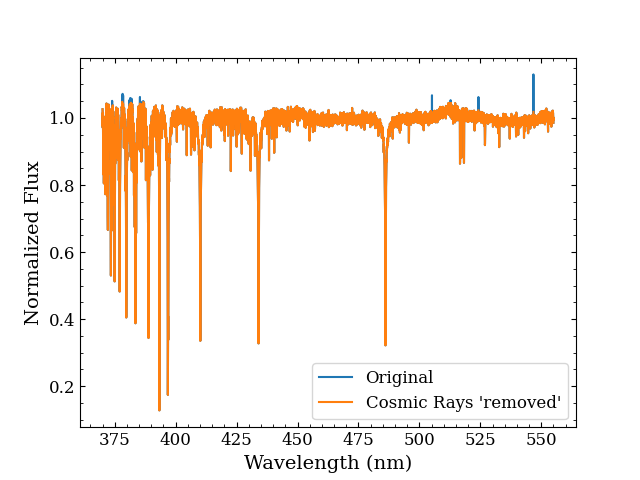

In [6]:
clipped_spectrum = sigma_clip(ra0103_s163_normflux, sigma_upper=0.7, sigma_lower=20, maxiters=5)

plt.figure()
plt.plot(ra0103_s163_wave, ra0103_s163_normflux, label='Original')
plt.plot(ra0103_s163_wave, clipped_spectrum, label="Cosmic Rays 'removed'")
plt.legend()
plt.xlabel('Wavelength (nm)')
plt.ylabel('Normalized Flux')
plt.show()

plt.savefig('/data/misfit/benlowe/results/cosmicray_test.png', dpi=300, transparent=False, facecolor='white')


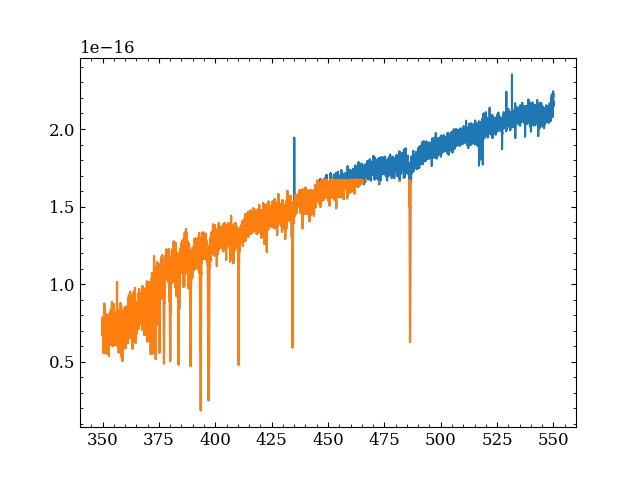

In [9]:
# def cosmic_remove(wavedata, fluxdata, window, wavemin, wavemax):
    
    

# Loading in test dataset
data = fits.open('/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_1633-2814_s284/uvb/ADP.2024-04-18T07:53:50.542.fits')
wave = data[1].data['WAVE'][0]
flux  = data[1].data['FLUX'][0]

wavemin = 350
wavemax = 550
waveindex = np.where((wave >= wavemin) & (wave <= wavemax))[0]
wavecut = wave[waveindex]
fluxcut = flux[waveindex]

plt.figure()
plt.plot(wavecut, fluxcut)

# # Normalize spectra by fitting polynomial
# x = np.arange(len(fluxcut))
# p = Polynomial.fit(wavecut, fluxcut, 3)
# cont = p(wavecut)
# plt.plot(wavecut, cont)

# normspec = fluxcut/cont
# plt.figure()
# plt.plot(wavecut, normspec)


# # Running sigma clipping
# avg = np.mean(fluxcut)

clipped_spectrum = sigma_clip(fluxcut, sigma_upper=1, sigma_lower=20, maxiters=5)
plt.plot(wavecut, clipped_spectrum)
plt.show()

1.536059512962825e-16


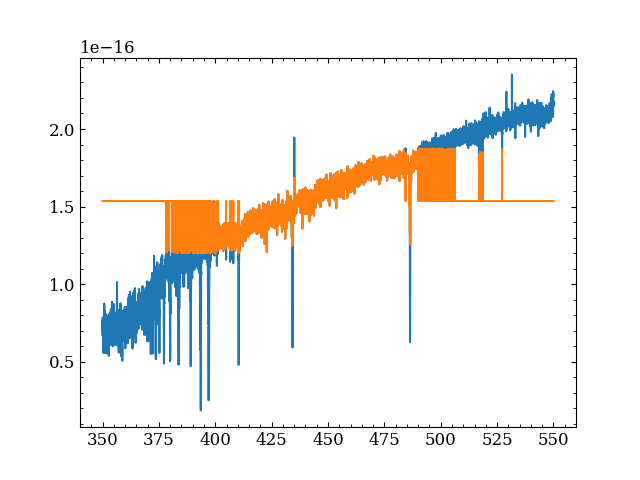

In [4]:
wavemin = 350
wavemax = 550
waveindex = np.where((wave >= wavemin) & (wave <= wavemax))[0]
wavecut = wave[waveindex]
fluxcut1 = flux[waveindex]
fluxcut2 = flux[waveindex]


avg = np.average(fluxcut2)
t = fluxcut2 - avg
print(avg)

threshold = 0.8 * np.std(fluxcut2)  # Define a 5σ threshold
cosmic_ray_mask = np.abs(fluxcut2 - avg) > threshold

fluxcut2[cosmic_ray_mask] = avg

plt.figure()
plt.plot(wavecut, fluxcut1)
plt.plot(wavecut, fluxcut2)

In [14]:
median_data = median_filter(fluxcut, size=3)  # Adjust kernel size as needed
cosmic_rays = fluxcut - median_data

threshold = 5 * np.std(cosmic_rays)  # Set a threshold for cosmic rays
cleaned_data = np.where(np.abs(cosmic_rays) > threshold, median_data, fluxcut)

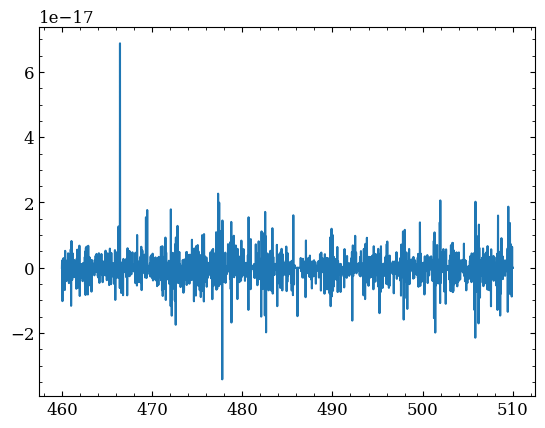

In [15]:
plt.figure()
plt.plot(wavecut, cosmic_rays)